# Example 5: Special functions

Let's construct a dataset which contains special functions $f(x,y)={\rm exp}(J_0(20x)+y^2)$, where $J_0(x)$ is the Bessel function.

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import refine
from xkan.symbolic import default_library, suggest_symbolic
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KANNetwork([2, 1, 1], grid=3, k=3, seed=2, device=device)
f = lambda x: torch.exp(torch.special.bessel_j0(20*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)

# train the model
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.5148237823643093 test RMSE 0.585271049412658


Plot trained KAN, the bessel function shows up in the bettom left

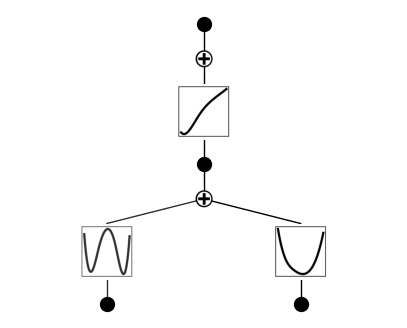

In [2]:
plot(model, train['x']);

In [3]:
model = refine(model, 20, train['x'])
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.015578971901857818 test RMSE 0.06706831626942916


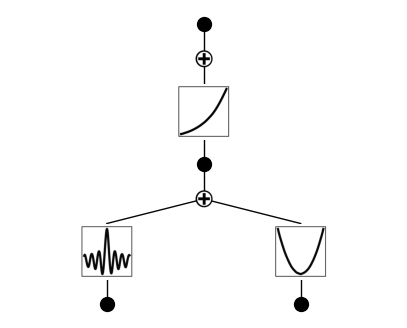

In [4]:
plot(model, train['x']);

`suggest_symbolic` finds no match because the default symbolic library (`default_library()`) has no Bessel function. The next cells add one.

In [5]:
suggest_symbolic(model, 0, 0, 0, train['x'])

        function        fitting r2           r2 loss        complexity        total loss
               0                 0       1.44269e-05                 0       2.88538e-06
               x       9.82293e-05      -0.000127294                 1          0.799975
           1/x^2          0.143303         -0.223127                 2           1.55537
             1/x         0.0878958         -0.132714                 2           1.57346
             cos         0.0833315         -0.125512                 2            1.5749


('0',
 SymbolicFunction(name='0', fn=<function <lambda> at 0x7ad7cc40d800>, sympy=<function <lambda> at 0x7ad7cc40d8a0>, complexity=0, singular=<function <lambda> at 0x7ad7cc40d940>),
 np.float64(0.0),
 np.int64(0))

In [6]:
lib = default_library()
list(lib.keys())

['x',
 'x^2',
 'x^3',
 'x^4',
 'x^5',
 '1/x',
 '1/x^2',
 '1/x^3',
 '1/x^4',
 '1/x^5',
 'sqrt',
 'x^0.5',
 'x^1.5',
 '1/sqrt(x)',
 '1/x^0.5',
 'exp',
 'log',
 'abs',
 'sin',
 'cos',
 'tan',
 'tanh',
 'sgn',
 'arcsin',
 'arccos',
 'arctan',
 'arctanh',
 '0',
 'gaussian']

Add the Bessel function J0 to the symbolic library with a name, a PyTorch implementation and a SymPy form. The last argument sets the complexity of J0.

In [7]:
import sympy

lib = lib.add('J0', torch.special.bessel_j0, sympy.Function('J0'), 1)

With Bessel in the library, run `suggest_symbolic` again (with `library=lib`).

In [8]:
# J0 fitting is not very good
suggest_symbolic(model, 0, 0, 0, train['x'], library=lib)

        function        fitting r2           r2 loss        complexity        total loss
               0                 0       1.44269e-05                 0       2.88538e-06
              J0          0.131556         -0.203478                 1          0.759304
               x       9.82293e-05      -0.000127294                 1          0.799975
           1/x^2          0.143303         -0.223127                 2           1.55537
             1/x         0.0878958         -0.132714                 2           1.57346


('0',
 SymbolicFunction(name='0', fn=<function <lambda> at 0x7ad7cc40d800>, sympy=<function <lambda> at 0x7ad7cc40d8a0>, complexity=0, singular=<function <lambda> at 0x7ad7cc40d940>),
 np.float64(0.0),
 np.int64(0))

The fitting r2 is still not high, this is because the ground truth is J0(20x) which involves 20 which is too large. our default search is in (-10,10). so we need to set the search range bigger in order to include 20. now J0 appears at the top of the list


In [9]:
suggest_symbolic(model, 0, 0, 0, train['x'], library=lib, a_range=(-40,40))

        function        fitting r2           r2 loss        complexity        total loss
              J0          0.998801          -9.69168                 1          -1.13834
               0                 0       1.44269e-05                 0       2.88538e-06
               x       9.82296e-05      -0.000127294                 1          0.799975
             cos          0.590709          -1.28876                 2           1.34225
             sin          0.590709          -1.28876                 2           1.34225


('J0',
 SymbolicFunction(name='J0', fn=<built-in function special_bessel_j0>, sympy=J0, complexity=1, singular=<function SymbolicLibrary.add.<locals>.<lambda> at 0x7ad5341e3b00>),
 np.float64(0.9988007545471191),
 np.int64(1))